In [1]:
# ============================================================
# CELL 0 — Install Required Packages
# ============================================================

%pip install -q requests joblib shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================================
# CELL 1 — Setup
# ============================================================

from pathlib import Path
import os,json,joblib,requests
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv

ROOT = Path.cwd()
while not (ROOT/"data").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent

MODEL_DIR = ROOT/"models"
GRAPH_DIR = ROOT/"graph"
XAI_DIR = ROOT/"xai"
FIG_DIR = ROOT/"figures/exploratory"
BACKEND_DIR = ROOT/"backend"

MODEL_PATH = MODEL_DIR/"best_improved_gat_lstm.pt"
CFG_PATH = MODEL_DIR/"gat_lstm_config.pkl"
SCALER_PATH = MODEL_DIR/"feature_scaler.pkl"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OW_KEY = os.getenv("OPENWEATHER_API_KEY","")

print("Device:",DEVICE)
print("OpenWeather key loaded:",bool(OW_KEY))

C:\Users\udish\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\udish\AppData\Roaming\Python\Python313\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cpu
OpenWeather key loaded: True


In [3]:
# ============================================================
# CELL 2 — Final Model + Graph
# ============================================================

cfg = joblib.load(CFG_PATH)
scaler = joblib.load(SCALER_PATH)

FEATURES = cfg["features"]
TARGETS = cfg["targets"]
SEQ_LEN = cfg["seq_len"]
STATIONS = cfg["station_list"]

target_mean = np.asarray(cfg["target_mean"])
target_std = np.asarray(cfg["target_std"])
res_mean = np.asarray(cfg["res_mean"])
res_std = np.asarray(cfg["res_std"])
fill_values = np.asarray(cfg["fill_values"])


# ------------------------------------------------------------
# Align station metadata and graph edges to saved model order
# ------------------------------------------------------------

STATIONS = [str(s) for s in STATIONS]
FEATURES = list(FEATURES)
TARGETS = list(TARGETS)
SEQ_LEN = int(SEQ_LEN)

EXPECTED_TARGETS = ["co", "no2", "o3", "pm10", "pm25", "so2"]
EXPECTED_WINDOWS = {
    "co": 8, "no2": 24, "o3": 8,
    "pm10": 24, "pm25": 24, "so2": 24,
}

if len(FEATURES) != 34:
    raise ValueError(f"Expected 34 base features, got {len(FEATURES)}.")

if TARGETS != EXPECTED_TARGETS:
    raise ValueError(f"Unexpected saved target order: {TARGETS}")

if SEQ_LEN != 24 or len(STATIONS) != 37:
    raise ValueError(
        f"Model configuration mismatch: sequence={SEQ_LEN}, "
        f"stations={len(STATIONS)}."
    )

if scaler.n_features_in_ != len(FEATURES):
    raise ValueError(
        "Saved scaler input dimension does not match the 34 base features."
    )

if fill_values.shape != (len(FEATURES),):
    raise ValueError("Unexpected feature imputation vector shape.")

if not np.isfinite(target_mean).all() or not np.isfinite(target_std).all():
    raise ValueError("Invalid target scaling values.")

if not np.isfinite(res_mean).all() or not np.isfinite(res_std).all():
    raise ValueError("Invalid residual scaling values.")

if (target_std <= 0).any() or (res_std <= 0).any():
    raise ValueError("Target/residual standard deviations must be positive.")

stations = pd.read_csv(GRAPH_DIR / "station_metadata_final.csv")
stations["location_id"] = stations["location_id"].astype(str)

if stations["location_id"].duplicated().any():
    raise ValueError("Station metadata contains duplicate station IDs.")

missing_stations = sorted(set(STATIONS) - set(stations["location_id"]))
extra_stations = sorted(set(stations["location_id"]) - set(STATIONS))

if missing_stations or extra_stations:
    raise ValueError(
        f"Station mismatch. Missing={missing_stations}, extra={extra_stations}"
    )

# Important: API coordinate ordering must match model station ordering.
stations = (
    stations.set_index("location_id")
    .loc[STATIONS]
    .reset_index()
)

edges = pd.read_csv(GRAPH_DIR / "edge_index_final.csv")
edges["source"] = edges["source"].astype(str)
edges["target"] = edges["target"].astype(str)

idx = {station: i for i, station in enumerate(STATIONS)}

edge_source = edges["source"].map(idx)
edge_target = edges["target"].map(idx)

if edge_source.isna().any() or edge_target.isna().any():
    raise ValueError("An edge references a station missing from the model.")

N = len(STATIONS)

EDGE_INDEX = torch.tensor(
    np.stack([
        edge_source.to_numpy(dtype=np.int64),
        edge_target.to_numpy(dtype=np.int64),
    ]),
    dtype=torch.long,
    device=DEVICE,
)

EDGE_ATTR = torch.tensor(
    edges["distance_km"].to_numpy(dtype=np.float32),
    dtype=torch.float32,
    device=DEVICE,
).view(-1, 1)

if EDGE_INDEX.shape != (2, 169):
    raise ValueError(f"Unexpected graph shape: {EDGE_INDEX.shape}")

if EDGE_ATTR.shape != (169, 1):
    raise ValueError(f"Unexpected edge-attribute shape: {EDGE_ATTR.shape}")

print("Configuration and graph aligned.")
print("Stations:", N)
print("Directed edges:", EDGE_INDEX.shape[1])
print("Features:", len(FEATURES))
print("Targets:", TARGETS)
print("Sequence length:", SEQ_LEN)

Configuration and graph aligned.
Stations: 37
Directed edges: 169
Features: 34
Targets: ['co', 'no2', 'o3', 'pm10', 'pm25', 'so2']
Sequence length: 24


C:\Users\udish\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
# ============================================================
# CELL 3 — Load Trained GAT-LSTM
# ============================================================

class ResidualGATLSTM(nn.Module):
    def __init__(self,Fdim,hidden=128,heads=4,drop=.2):
        super().__init__()
        self.lstm=nn.LSTM(Fdim,hidden,2,batch_first=True,dropout=drop)
        self.emb=nn.Embedding(N,16)
        self.gat1=GATv2Conv(hidden+16,hidden//heads,heads=heads,edge_dim=1)
        self.gat2=GATv2Conv(hidden,hidden,edge_dim=1)
        self.n1=nn.LayerNorm(hidden); self.n2=nn.LayerNorm(hidden)
        self.drop=nn.Dropout(drop)
        self.heads=nn.ModuleList([
            nn.Sequential(nn.Linear(hidden,64),nn.SiLU(),nn.Dropout(drop),nn.Linear(64,1))
            for _ in TARGETS
        ])

    def forward(self,x,edge_index,edge_attr):
        B,T,Nn,Fdim=x.shape
        z=x.permute(0,2,1,3).reshape(B*Nn,T,Fdim)
        h,_=self.lstm(z); h=h[:,-1].view(B,Nn,-1)
        e=self.emb(torch.arange(N,device=h.device)).unsqueeze(0).expand(B,-1,-1)
        h=torch.cat([h,e],-1).reshape(B*Nn,-1)
        off=torch.arange(B,device=h.device)*N
        ei=torch.cat([edge_index+o for o in off],1)
        ea=edge_attr.repeat(B,1)
        z=F.elu(self.gat1(h,ei,edge_attr=ea))
        z=self.drop(self.n1(z))
        z=self.gat2(z,ei,edge_attr=ea)
        z=self.n2(z+h[:,:z.shape[1]])
        z=self.drop(z).view(B,Nn,-1)
        return torch.cat([head(z) for head in self.heads],-1)


model = ResidualGATLSTM(46).to(DEVICE)

state = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(state, strict=True)
model.eval()

print("Loaded trained GAT-LSTM.")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Loaded trained GAT-LSTM.
Parameters: 344,150


In [5]:
# ============================================================
# CELL 4 — OpenWeather 48H Pollutant History
# ============================================================

from datetime import datetime,timedelta,timezone

if not OW_KEY: raise ValueError("OPENWEATHER_API_KEY not found.")

end=int(datetime.now(timezone.utc).timestamp())
start=int((datetime.now(timezone.utc)-timedelta(hours=48)).timestamp())
ow_rows=[]

for _,s in stations.iterrows():
    r=requests.get(
        "https://api.openweathermap.org/data/2.5/air_pollution/history",
        params={"lat":s.latitude,"lon":s.longitude,"start":start,"end":end,"appid":OW_KEY},
        timeout=30
    )
    r.raise_for_status()
    for x in r.json().get("list",[]):
        ow_rows.append({
            "location_id":s.location_id,
            "time":pd.to_datetime(x["dt"],unit="s",utc=True),
            **x["components"]
        })

ow=pd.DataFrame(ow_rows).rename(columns={"pm2_5":"pm25"})
ow["co"]/=1000

print("Rows:",len(ow))
print("Stations:",ow.location_id.nunique())
print("Hours:",ow.time.nunique())
print("Missing:",ow[TARGETS].isna().sum().sum())

Rows: 1776
Stations: 37
Hours: 48
Missing: 0


In [6]:
# ============================================================
# CELL 5 — OpenWeather Current Observation
# ============================================================

cur_rows=[]

for _,s in stations.iterrows():
    r=requests.get(
        "https://api.openweathermap.org/data/2.5/air_pollution",
        params={"lat":s.latitude,"lon":s.longitude,"appid":OW_KEY},
        timeout=30
    )
    r.raise_for_status()
    x=r.json()["list"][0]
    cur_rows.append({
        "location_id":s.location_id,
        "time":pd.to_datetime(x["dt"],unit="s",utc=True),
        **x["components"]
    })

ow_cur=pd.DataFrame(cur_rows).rename(columns={"pm2_5":"pm25"})
ow_cur["co"]/=1000

print("Stations:",len(ow_cur))
print("Latest:",ow_cur.time.min(),"→",ow_cur.time.max())
print("Missing:",ow_cur[TARGETS].isna().sum().sum())

Stations: 37
Latest: 2026-10-21 11:42:58+00:00 → 2026-10-21 11:47:32+00:00
Missing: 0


In [7]:
# ============================================================
# CELL 6 — Open-Meteo Weather
# ============================================================

WX_URL="https://api.open-meteo.com/v1/forecast"

lat=",".join(stations.latitude.astype(str))
lng=",".join(stations.longitude.astype(str))

params={
    "latitude":lat,"longitude":lng,
    "hourly":",".join([
        "temperature_2m","dew_point_2m","surface_pressure",
        "precipitation","wind_speed_10m","wind_direction_10m",
        "boundary_layer_height"
    ]),
    "past_hours":48,"forecast_hours":73,"timezone":"UTC"
}

r=requests.get(WX_URL,params=params,timeout=60)
r.raise_for_status()

wx_rows=[]
data=r.json()

for i,s in enumerate(STATIONS):
    d=pd.DataFrame(data[i]["hourly"])
    d["location_id"]=s
    wx_rows.append(d)

wx=pd.concat(wx_rows,ignore_index=True)
wx["time"]=pd.to_datetime(wx.time,utc=True)

wx=wx.rename(columns={
    "temperature_2m":"era5_t2m_c",
    "dew_point_2m":"era5_d2m_c",
    "surface_pressure":"era5_sp_hpa",
    "precipitation":"era5_tp_mm",
    "wind_speed_10m":"era5_wind_speed",
    "wind_direction_10m":"era5_wind_dir",
    "boundary_layer_height":"era5_blh"
})

print("Rows:",len(wx))
print("Stations:",wx.location_id.nunique())
print("Hours:",wx.time.nunique())
print("Missing:",wx.isna().sum().sum())

Rows: 4477
Stations: 37
Hours: 121
Missing: 0


In [8]:

# ============================================================
# CELL 7 — Live Data Merge (Hourly, Station-Aligned)
# ============================================================

hist = ow.copy()
cur = ow_cur.copy()
weather = wx.copy()

for frame in [hist, cur, weather]:
    frame["location_id"] = frame["location_id"].astype(str)
    frame["time"] = (
        pd.to_datetime(frame["time"], utc=True)
        .dt.floor("h")
    )

# Keep only the pollutant columns required by the model and AQI logic.
hist = hist[["location_id", "time"] + TARGETS]
cur = cur[["location_id", "time"] + TARGETS]

# Historical data first, current observation second, so current data
# replaces history only for the same station and hour.
poll = pd.concat([hist, cur], ignore_index=True)

poll = (
    poll.drop_duplicates(
        ["location_id", "time"],
        keep="last",
    )
    .sort_values(["location_id", "time"])
    .reset_index(drop=True)
)

weather = (
    weather.drop_duplicates(
        ["location_id", "time"],
        keep="last",
    )
    .sort_values(["location_id", "time"])
    .reset_index(drop=True)
)

poll = poll.dropna(subset=["location_id", "time"])
weather = weather.dropna(subset=["location_id", "time"])

if poll.empty or weather.empty:
    raise ValueError("The live pollutant or weather data is empty.")

# Use the overlapping time range available in both data sources.
start_time = max(poll["time"].min(), weather["time"].min()).ceil("h")
end_time = min(poll["time"].max(), weather["time"].max()).floor("h")

if start_time > end_time:
    raise ValueError("Pollutant and weather feeds have no overlapping hours.")

hourly_times = pd.date_range(start_time, end_time, freq="h")

grid = pd.MultiIndex.from_product(
    [hourly_times, STATIONS],
    names=["time", "location_id"],
)

grid_df = grid.to_frame(index=False)

# Left joins preserve each expected station-hour. Missing observations
# remain NaN, and are later handled by the model's masking/imputation.
live = (
    grid_df
    .merge(
        poll,
        on=["location_id", "time"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        weather,
        on=["location_id", "time"],
        how="left",
        validate="one_to_one",
    )
)

coordinate_lookup = stations.set_index("location_id")

live["latitude"] = live["location_id"].map(coordinate_lookup["latitude"])
live["longitude"] = live["location_id"].map(coordinate_lookup["longitude"])

live = live.sort_values(
    ["location_id", "time"]
).reset_index(drop=True)

expected_rows = len(hourly_times) * N

if len(live) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows} hourly station rows, got {len(live)}."
    )

if live.duplicated(["location_id", "time"]).any():
    raise ValueError("Duplicate station-hour rows remain after alignment.")

if live["location_id"].nunique() != N:
    raise ValueError("Not all model stations are present in the live grid.")

print("=" * 65)
print("LIVE DATA ALIGNED")
print("=" * 65)
print("Rows:", f"{len(live):,}")
print("Stations:", live["location_id"].nunique())
print("Hours:", live["time"].nunique())
print("Range:", live["time"].min(), "→", live["time"].max())
print("Missing pollutant values:", int(live[TARGETS].isna().sum().sum()))
print("Missing weather values:", int(
    live.drop(columns=TARGETS).isna().sum().sum()
))


LIVE DATA ALIGNED
Rows: 1,776
Stations: 37
Hours: 48
Range: 2026-10-19 12:00:00+00:00 → 2026-10-21 11:00:00+00:00
Missing pollutant values: 0
Missing weather values: 0


In [9]:

# ============================================================
# CELL 8 — Live Feature Engineering
# ============================================================

live = live.sort_values(
    ["location_id", "time"]
).reset_index(drop=True)

live["hour"] = live["time"].dt.hour
live["month"] = live["time"].dt.month
live["dayofweek"] = live["time"].dt.dayofweek

live["hour_sin"] = np.sin(2 * np.pi * live["hour"] / 24)
live["hour_cos"] = np.cos(2 * np.pi * live["hour"] / 24)
live["dow_sin"] = np.sin(2 * np.pi * live["dayofweek"] / 7)
live["dow_cos"] = np.cos(2 * np.pi * live["dayofweek"] / 7)

for pollutant in TARGETS:

    grouped = live.groupby("location_id", sort=False)[pollutant]

    live[f"{pollutant}_lag1"] = grouped.shift(1)
    live[f"{pollutant}_lag24"] = grouped.shift(24)

    # Rolling 24-hour mean from prior hours only, computed independently
    # for every station. The continuous hourly grid is essential here.
    live[f"{pollutant}_roll24_mean"] = (
        live.groupby("location_id", sort=False)[pollutant]
        .transform(
            lambda s: s.shift(1).rolling(
                window=24,
                min_periods=1,
            ).mean()
        )
    )

missing_features = [
    feature for feature in FEATURES
    if feature not in live.columns
]

if missing_features:
    raise ValueError(
        f"Live feature engineering failed to create: {missing_features}"
    )

print("Required model features:", len(FEATURES))
print("Missing feature columns:", len(missing_features))
print("Feature engineering complete.")


Required model features: 34
Missing feature columns: 0
Feature engineering complete.


In [10]:

# ============================================================
# CELL 9 — Current 24H Model Tensor
# ============================================================

latest = live["time"].max()

window = pd.date_range(
    latest - pd.Timedelta(hours=SEQ_LEN - 1),
    latest,
    freq="h",
)

if len(window) != SEQ_LEN:
    raise ValueError("The live input window is not 24 hours.")

grid = pd.MultiIndex.from_product(
    [window, STATIONS],
    names=["time", "location_id"],
)

z = (
    live.set_index(["time", "location_id"])
    .reindex(grid)
)

base = z[FEATURES].replace([np.inf, -np.inf], np.nan)

fill_series = pd.Series(
    fill_values,
    index=FEATURES,
)

base = base.fillna(fill_series)

base_values = base.to_numpy(dtype=np.float32)

if not np.isfinite(base_values).all():
    raise ValueError("Base feature tensor still contains invalid values.")

base_scaled = scaler.transform(base_values).astype(np.float32)

hist_values = z[TARGETS].to_numpy(dtype=np.float32)
availability = np.isfinite(hist_values).astype(np.float32)

hist_scaled = (
    hist_values - target_mean.astype(np.float32)
) / target_std.astype(np.float32)

hist_scaled = np.nan_to_num(
    hist_scaled,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
).astype(np.float32)

X46 = np.concatenate(
    [base_scaled, hist_scaled, availability],
    axis=1,
).reshape(SEQ_LEN, N, 46)

if not np.isfinite(X46).all():
    raise ValueError("Final model input contains non-finite values.")

x_live = torch.tensor(
    X46[None],
    dtype=torch.float32,
    device=DEVICE,
)

assert x_live.shape == (1, 24, 37, 46)

print("Latest:", latest)
print("Window:", window[0], "→", window[-1])
print("Tensor:", tuple(x_live.shape))
print("Missing pollutant-history values:", int(
    np.isnan(hist_values).sum()
))
print("Availability-mask zeros:", int((availability == 0).sum()))
print("Finite input:", bool(torch.isfinite(x_live).all()))


Latest: 2026-10-21 11:00:00+00:00
Window: 2026-10-20 12:00:00+00:00 → 2026-10-21 11:00:00+00:00
Tensor: (1, 24, 37, 46)
Missing pollutant-history values: 0
Availability-mask zeros: 0
Finite input: True


In [11]:

# ============================================================
# CELL 10 — Next-Hour Pollutant Forecast
# ============================================================

with torch.no_grad():
    raw = model(
        x_live,
        EDGE_INDEX,
        EDGE_ATTR,
    )[0].cpu().numpy()

if raw.shape != (N, len(TARGETS)):
    raise ValueError(f"Unexpected prediction shape: {raw.shape}")

if not np.isfinite(raw).all():
    raise ValueError("The model returned non-finite residual predictions.")

last = (
    live.loc[live["time"] == latest]
    .set_index("location_id")[TARGETS]
    .reindex(STATIONS)
)

pred = np.empty((N, len(TARGETS)), dtype=np.float64)

for k, pollutant in enumerate(TARGETS):

    # Match the missing-residual-baseline handling used in Notebook 7.
    previous = last[pollutant].to_numpy(dtype=float)
    previous = np.nan_to_num(
        previous,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )

    pred[:, k] = (
        raw[:, k] * res_std[k]
        + res_mean[k]
        + previous
    )

# Physical non-negativity constraint for concentrations.
pred = np.clip(pred, 0.0, None)

if not np.isfinite(pred).all():
    raise ValueError("Next-hour pollutant forecast contains invalid values.")

next_df = pd.DataFrame(
    pred,
    index=STATIONS,
    columns=TARGETS,
)

forecast_utc = latest + pd.Timedelta(hours=1)
forecast_ist = forecast_utc.tz_convert("Asia/Kolkata")

print("Forecast UTC:", forecast_utc)
print("Forecast IST:", forecast_ist)
display(next_df.round(3))


Forecast UTC: 2026-10-21 12:00:00+00:00
Forecast IST: 2026-10-21 17:30:00+05:30


,co,no2,o3,pm10,pm25,so2
ST01,0.431,20.493,92.803,80.624,44.290,4.029
ST02,0.504,27.356,80.257,86.691,46.784,4.545
ST03,0.510,25.727,82.509,93.415,49.671,4.863
ST04,0.352,16.196,89.506,64.707,38.153,3.455
ST05,0.459,23.405,83.005,75.555,42.539,3.980
ST06,0.396,19.453,88.131,69.849,40.332,3.940
ST07,0.434,21.477,85.380,75.059,41.656,3.841
ST08,0.465,25.601,81.074,78.063,44.061,4.253
ST09,0.403,21.238,85.546,69.834,41.172,3.930
ST10,0.501,27.076,78.718,79.996,45.081,4.395


In [12]:
# ============================================================
# CELL 11 — CPCB AQI
# ============================================================

AQI_BP = cfg["aqi_breakpoints"]

AQI_WINDOW_HOURS = cfg.get(
    "aqi_window_hours",
    {
        "co": 8, "o3": 8,
        "no2": 24, "pm10": 24,
        "pm25": 24, "so2": 24,
    }
)

AQI_CATS = [
    "Good", "Satisfactory", "Moderately polluted",
    "Poor", "Very Poor", "Severe"
]


def cpcb_subindex(values, pollutant):

    values = np.asarray(values, dtype=float)
    out = np.full(values.shape, np.nan, dtype=float)

    valid_values = np.isfinite(values) & (values >= 0)

    for i, (lo, hi, ilo, ihi) in enumerate(AQI_BP[pollutant]):

        if i == 0:
            in_band = (values >= lo) & (values <= hi)
        elif np.isfinite(hi):
            in_band = (values > lo) & (values <= hi)
        else:
            in_band = values > lo

        use = valid_values & in_band & np.isnan(out)

        if not np.any(use):
            continue

        if np.isinf(hi):
            out[use] = 500.0
        else:
            out[use] = (
                ilo
                + (ihi - ilo) * (values[use] - lo) / (hi - lo)
            )

    return np.floor(out)


def cpcb_aqi_timeline(source):

    """
    Calculate CPCB-period AQI for a multi-station hourly timeline.

    source must contain:
        location_id, time, and all six pollutant columns.

    Each station is reindexed to a continuous hourly timeline.
    A period average is valid only when its complete 8-hour or
    24-hour concentration window is available.
    """

    required = ["location_id", "time"] + TARGETS

    missing = [
        col for col in required
        if col not in source.columns
    ]

    if missing:
        raise ValueError(
            f"AQI source is missing required columns: {missing}"
        )

    data = source[required].copy()

    data["time"] = pd.to_datetime(
        data["time"], utc=True
    )

    data = data.dropna(
        subset=["location_id", "time"]
    )

    data = data.drop_duplicates(
        ["location_id", "time"],
        keep="last"
    )

    output = []

    for station_id, group in data.groupby(
        "location_id", sort=False
    ):

        g = (
            group[["time"] + TARGETS]
            .set_index("time")
            .sort_index()
        )

        if g.empty:
            continue

        hourly_index = pd.date_range(
            g.index.min().floor("h"),
            g.index.max().ceil("h"),
            freq="h"
        )

        g = g.reindex(hourly_index)
        g.index.name = "time"

        subindices = {}

        for pollutant in TARGETS:

            window = AQI_WINDOW_HOURS[pollutant]

            rolling_mean = g[pollutant].rolling(
                window=window,
                min_periods=window
            ).mean()

            subindices[pollutant] = cpcb_subindex(
                rolling_mean.to_numpy(),
                pollutant
            )

        SI = np.column_stack([
            subindices[pollutant]
            for pollutant in TARGETS
        ])

        # Match the strict complete-window rule used in
        # the research evaluation notebooks.
        valid = np.isfinite(SI).all(axis=1)

        AQI = np.full(len(g), np.nan, dtype=float)

        AQI[valid] = np.max(
            SI[valid], axis=1
        )

        dominant = np.full(
            len(g), None, dtype=object
        )

        dominant[valid] = np.asarray(
            TARGETS, dtype=object
        )[np.argmax(SI[valid], axis=1)]

        category = []

        for value in AQI:

            if not np.isfinite(value):
                category.append(None)
            elif value <= 50:
                category.append("Good")
            elif value <= 100:
                category.append("Satisfactory")
            elif value <= 200:
                category.append("Moderately polluted")
            elif value <= 300:
                category.append("Poor")
            elif value <= 400:
                category.append("Very Poor")
            else:
                category.append("Severe")

        output.append(pd.DataFrame({
            "location_id": station_id,
            "time": g.index,
            "AQI": AQI,
            "category": category,
            "dominant_pollutant": dominant,
        }))

    if not output:
        raise ValueError(
            "No station data available for CPCB AQI calculation."
        )

    return pd.concat(
        output,
        ignore_index=True
    )


# ------------------------------------------------------------
# Next-hour CPCB AQI
# Combine observed history with next-hour predictions.
# ------------------------------------------------------------

next_pollutants = (
    next_df.copy()
    .rename_axis("location_id")
    .reset_index()
)

next_pollutants["time"] = forecast_utc

aqi_source = pd.concat(
    [
        live[["location_id", "time"] + TARGETS],
        next_pollutants[["location_id", "time"] + TARGETS],
    ],
    ignore_index=True
)

aqi_timeline = cpcb_aqi_timeline(aqi_source)

aqi_df = (
    aqi_timeline[
        aqi_timeline.time == forecast_utc
    ][
        [
            "location_id", "AQI",
            "category", "dominant_pollutant"
        ]
    ]
    .rename(columns={"location_id": "station"})
    .reset_index(drop=True)
)

if len(aqi_df) != N:
    raise ValueError(
        f"Expected {N} next-hour AQI rows, got {len(aqi_df)}."
    )

if aqi_df["AQI"].isna().any():
    missing_stations = aqi_df.loc[
        aqi_df.AQI.isna(), "station"
    ].tolist()

    raise ValueError(
        "CPCB AQI could not be calculated for stations with "
        "incomplete pollutant averaging windows: "
        f"{missing_stations[:10]}"
    )

print("Forecast UTC:", forecast_utc)
print("Forecast IST:", forecast_ist)
print("Averaging windows:", AQI_WINDOW_HOURS)

display(aqi_df)

Forecast UTC: 2026-10-21 12:00:00+00:00
Forecast IST: 2026-10-21 17:30:00+05:30
Averaging windows: {'co': 8, 'no2': 24, 'o3': 8, 'pm10': 24, 'pm25': 24, 'so2': 24}


,station,AQI,category,dominant_pollutant
0,ST01,130.0,Moderately polluted,o3
1,ST02,125.0,Moderately polluted,o3
2,ST03,129.0,Moderately polluted,o3
3,ST04,128.0,Moderately polluted,o3
4,ST05,126.0,Moderately polluted,o3
5,ST06,127.0,Moderately polluted,o3
6,ST07,127.0,Moderately polluted,o3
7,ST08,125.0,Moderately polluted,o3
8,ST09,126.0,Moderately polluted,o3
9,ST10,125.0,Moderately polluted,o3


In [13]:
# ============================================================
# CELL 12 — Next-Hour Result
# ============================================================

next_result=next_df.copy()
aq=aqi_df.set_index("station")

next_result["AQI"]=aq.loc[next_result.index,"AQI"]
next_result["category"]=aq.loc[next_result.index,"category"]
next_result["dominant"]=aq.loc[next_result.index,"dominant_pollutant"]
next_result.index.name="station"

print("Forecast:",forecast_ist)
display(next_result.round(3))

Forecast: 2026-10-21 17:30:00+05:30


,co,no2,o3,pm10,pm25,so2,AQI,category,dominant
station,,,,,,,,,
ST01,0.431,20.493,92.803,80.624,44.290,4.029,130.0,Moderately polluted,o3
ST02,0.504,27.356,80.257,86.691,46.784,4.545,125.0,Moderately polluted,o3
ST03,0.510,25.727,82.509,93.415,49.671,4.863,129.0,Moderately polluted,o3
ST04,0.352,16.196,89.506,64.707,38.153,3.455,128.0,Moderately polluted,o3
ST05,0.459,23.405,83.005,75.555,42.539,3.980,126.0,Moderately polluted,o3
ST06,0.396,19.453,88.131,69.849,40.332,3.940,127.0,Moderately polluted,o3
ST07,0.434,21.477,85.380,75.059,41.656,3.841,127.0,Moderately polluted,o3
ST08,0.465,25.601,81.074,78.063,44.061,4.253,125.0,Moderately polluted,o3
ST09,0.403,21.238,85.546,69.834,41.172,3.930,126.0,Moderately polluted,o3


In [14]:

# ============================================================
# CELL 13 — 72H Weather Preparation
# ============================================================

future_times = pd.date_range(
    latest + pd.Timedelta(hours=1),
    latest + pd.Timedelta(hours=72),
    freq="h",
)

future_wx = wx.loc[
    wx["time"].isin(future_times)
].copy()

future_wx["location_id"] = future_wx["location_id"].astype(str)

if future_wx.duplicated(["location_id", "time"]).any():
    raise ValueError("Duplicate future weather rows found.")

counts = future_wx.groupby("time")["location_id"].nunique()
missing_times = future_times.difference(
    pd.DatetimeIndex(counts.index)
)

incomplete_times = counts[counts != N]

if len(missing_times) or len(incomplete_times):
    raise ValueError(
        f"Incomplete 72-hour weather coverage. "
        f"Missing timestamps={len(missing_times)}, "
        f"incomplete station-hours={len(incomplete_times)}. "
        "Check the Open-Meteo response before forecasting."
    )

expected_rows = 72 * N

if len(future_wx) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows} future weather rows, "
        f"received {len(future_wx)}."
    )

print("Future weather coverage verified.")
print("Rows:", len(future_wx))
print("Stations per hour:", N)
print("Hours:", future_wx["time"].nunique())
print("Range:", future_wx["time"].min(), "→", future_wx["time"].max())
print("Missing weather values:", int(future_wx.isna().sum().sum()))


Future weather coverage verified.
Rows: 2664
Stations per hour: 37
Hours: 72
Range: 2026-10-21 12:00:00+00:00 → 2026-10-24 11:00:00+00:00
Missing weather values: 0


In [15]:

# ============================================================
# CELL 14 — 72H Recursive Forecast
# ============================================================

hist = live.copy()
future_rows = []

weather_cols = [
    "location_id", "time", "latitude", "longitude",
    "era5_t2m_c", "era5_d2m_c", "era5_sp_hpa", "era5_tp_mm",
    "era5_wind_speed", "era5_wind_dir", "era5_blh",
]

for t in future_times:

    fw = future_wx.loc[future_wx["time"] == t].copy()

    fw = fw.merge(
        stations[["location_id", "latitude", "longitude"]],
        on="location_id",
        how="left",
        validate="one_to_one",
    )

    if len(fw) != N or fw["location_id"].nunique() != N:
        raise ValueError(f"Incomplete station weather for {t}.")

    fw[TARGETS] = np.nan
    fw = fw[weather_cols + TARGETS]

    # Reset indices because concatenating station frames can otherwise
    # leave duplicate row labels that misalign feature assignments.
    win = (
        pd.concat([hist, fw], ignore_index=True)
        .sort_values(["location_id", "time"])
        .reset_index(drop=True)
    )

    if win.duplicated(["location_id", "time"]).any():
        raise ValueError(f"Duplicate station-time rows in recursive input at {t}.")

    win["hour"] = win["time"].dt.hour
    win["month"] = win["time"].dt.month
    win["dayofweek"] = win["time"].dt.dayofweek

    win["hour_sin"] = np.sin(2 * np.pi * win["hour"] / 24)
    win["hour_cos"] = np.cos(2 * np.pi * win["hour"] / 24)
    win["dow_sin"] = np.sin(2 * np.pi * win["dayofweek"] / 7)
    win["dow_cos"] = np.cos(2 * np.pi * win["dayofweek"] / 7)

    # Recompute pollutant lags and rolling means independently by station.
    for pollutant in TARGETS:

        grouped = win.groupby(
            "location_id",
            sort=False,
        )[pollutant]

        win[f"{pollutant}_lag1"] = grouped.shift(1)
        win[f"{pollutant}_lag24"] = grouped.shift(24)

        win[f"{pollutant}_roll24_mean"] = (
            win.groupby("location_id", sort=False)[pollutant]
            .transform(
                lambda s: s.shift(1).rolling(
                    window=24,
                    min_periods=1,
                ).mean()
            )
        )

    input_window = pd.date_range(
        t - pd.Timedelta(hours=SEQ_LEN),
        t - pd.Timedelta(hours=1),
        freq="h",
    )

    grid = pd.MultiIndex.from_product(
        [input_window, STATIONS],
        names=["time", "location_id"],
    )

    z = (
        win.set_index(["time", "location_id"])
        .reindex(grid)
    )

    base = z[FEATURES].replace([np.inf, -np.inf], np.nan)
    base = base.fillna(pd.Series(fill_values, index=FEATURES))

    base_values = base.to_numpy(dtype=np.float32)

    if not np.isfinite(base_values).all():
        raise ValueError(f"Invalid base features in recursive input at {t}.")

    base_scaled = scaler.transform(base_values).astype(np.float32)

    yy = z[TARGETS].to_numpy(dtype=np.float32)
    availability = np.isfinite(yy).astype(np.float32)

    yy_scaled = (
        yy - target_mean.astype(np.float32)
    ) / target_std.astype(np.float32)

    yy_scaled = np.nan_to_num(
        yy_scaled,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    ).astype(np.float32)

    X = np.concatenate(
        [base_scaled, yy_scaled, availability],
        axis=1,
    ).reshape(SEQ_LEN, N, 46)

    if not np.isfinite(X).all():
        raise ValueError(f"Invalid 46-channel input for forecast time {t}.")

    xt = torch.tensor(
        X[None],
        dtype=torch.float32,
        device=DEVICE,
    )

    with torch.no_grad():
        raw = model(
            xt,
            EDGE_INDEX,
            EDGE_ATTR,
        )[0].cpu().numpy()

    if raw.shape != (N, len(TARGETS)) or not np.isfinite(raw).all():
        raise ValueError(f"Invalid model output at forecast time {t}.")

    previous_frame = (
        hist.loc[hist["time"] == hist["time"].max()]
        .set_index("location_id")[TARGETS]
        .reindex(STATIONS)
    )

    out = np.empty((N, len(TARGETS)), dtype=np.float64)

    for k, pollutant in enumerate(TARGETS):

        previous = previous_frame[pollutant].to_numpy(dtype=float)

        previous = np.nan_to_num(
            previous,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

        out[:, k] = (
            raw[:, k] * res_std[k]
            + res_mean[k]
            + previous
        )

    out = np.clip(out, 0.0, None)

    if not np.isfinite(out).all():
        raise ValueError(f"Forecast contains invalid concentrations at {t}.")

    pred_rows = fw.copy()
    pred_rows[TARGETS] = out

    hist = pd.concat(
        [hist, pred_rows],
        ignore_index=True,
    )

    future_rows.append(
        pred_rows[["location_id", "time"] + TARGETS]
    )

forecast = pd.concat(
    future_rows,
    ignore_index=True,
)

if len(forecast) != 72 * N:
    raise ValueError(f"Expected {72 * N} forecast rows, got {len(forecast)}.")

if forecast.duplicated(["location_id", "time"]).any():
    raise ValueError("Duplicate station-time rows in final forecast.")

if forecast[TARGETS].isna().any().any():
    raise ValueError("Final 72-hour pollutant forecast contains missing values.")

if (forecast[TARGETS] < 0).any().any():
    raise ValueError("Negative pollutant values remain after post-processing.")

print("=" * 65)
print("72-HOUR RECURSIVE FORECAST COMPLETE")
print("=" * 65)
print("Rows:", len(forecast))
print("Stations:", forecast["location_id"].nunique())
print("Hours:", forecast["time"].nunique())
print("Range:", forecast["time"].min(), "→", forecast["time"].max())
print("Finite pollutant predictions:", bool(np.isfinite(
    forecast[TARGETS].to_numpy(dtype=float)
).all()))


72-HOUR RECURSIVE FORECAST COMPLETE
Rows: 2664
Stations: 37
Hours: 72
Range: 2026-10-21 12:00:00+00:00 → 2026-10-24 11:00:00+00:00
Finite pollutant predictions: True


In [16]:
# ============================================================
# CELL 15 — 72H CPCB AQI
# ============================================================

# Combine observed pollutant history with recursive forecasts.
aqi_source = pd.concat(
    [
        live[["location_id", "time"] + TARGETS],
        forecast[["location_id", "time"] + TARGETS],
    ],
    ignore_index=True
)

aqi_timeline = cpcb_aqi_timeline(aqi_source)

# Retain exactly the timestamps belonging to the 72-hour forecast.
forecast_aqi = (
    forecast[["location_id", "time"]]
    .merge(
        aqi_timeline[
            [
                "location_id", "time", "AQI",
                "category", "dominant_pollutant"
            ]
        ],
        on=["location_id", "time"],
        how="left",
        validate="one_to_one"
    )
    .sort_values(
        ["location_id", "time"]
    )
    .reset_index(drop=True)
)

if len(forecast_aqi) != len(forecast):
    raise ValueError(
        "The CPCB AQI result count does not match the forecast."
    )

if forecast_aqi["AQI"].isna().any():
    missing = int(
        forecast_aqi["AQI"].isna().sum()
    )

    raise ValueError(
        f"{missing} forecast rows lack complete CPCB-period "
        "pollutant windows. Inspect the live history and forecast."
    )

print("=" * 60)
print("72H CPCB-PERIOD AQI FORECAST")
print("=" * 60)

print("Rows:", len(forecast_aqi))
print("Stations:", forecast_aqi.location_id.nunique())
print("Hours:", forecast_aqi.time.nunique())
print("Range:", forecast_aqi.time.min(), "→", forecast_aqi.time.max())
print("AQI averaging windows:", AQI_WINDOW_HOURS)

display(forecast_aqi.head(37))

72H CPCB-PERIOD AQI FORECAST
Rows: 2664
Stations: 37
Hours: 72
Range: 2026-10-21 12:00:00+00:00 → 2026-10-24 11:00:00+00:00
AQI averaging windows: {'co': 8, 'no2': 24, 'o3': 8, 'pm10': 24, 'pm25': 24, 'so2': 24}


,location_id,time,AQI,category,dominant_pollutant
0,ST01,2026-10-21 12:00:00+00:00,130.0,Moderately polluted,o3
1,ST01,2026-10-21 13:00:00+00:00,130.0,Moderately polluted,o3
2,ST01,2026-10-21 14:00:00+00:00,126.0,Moderately polluted,o3
3,ST01,2026-10-21 15:00:00+00:00,116.0,Moderately polluted,o3
4,ST01,2026-10-21 16:00:00+00:00,107.0,Moderately polluted,o3
5,ST01,2026-10-21 17:00:00+00:00,97.0,Satisfactory,o3
6,ST01,2026-10-21 18:00:00+00:00,92.0,Satisfactory,pm10
7,ST01,2026-10-21 19:00:00+00:00,94.0,Satisfactory,pm10
8,ST01,2026-10-21 20:00:00+00:00,98.0,Satisfactory,pm10
9,ST01,2026-10-21 21:00:00+00:00,102.0,Moderately polluted,pm10


In [17]:
# ============================================================
# CELL 16 — 72H Forecast Sanity Check
# ============================================================

summary=(
    forecast.merge(forecast_aqi,on=["location_id","time"])
    .groupby("time")
    .agg(
        mean_pm25=("pm25","mean"),
        mean_pm10=("pm10","mean"),
        mean_aqi=("AQI","mean"),
        max_aqi=("AQI","max")
    )
    .reset_index()
)

print("AQI range:",summary.mean_aqi.min(),"→",summary.mean_aqi.max())
display(summary.head())
display(summary.tail())

AQI range: 92.16216216216216 → 209.1081081081081


,time,mean_pm25,mean_pm10,mean_aqi,max_aqi
0,2026-10-21 12:00:00+00:00,43.414416,77.208006,126.405405,131.0
1,2026-10-21 13:00:00+00:00,45.992292,83.401962,124.891892,132.0
2,2026-10-21 14:00:00+00:00,48.385593,88.769571,119.540541,128.0
3,2026-10-21 15:00:00+00:00,49.318305,91.388229,108.486486,117.0
4,2026-10-21 16:00:00+00:00,49.228276,92.949716,99.000000,116.0


,time,mean_pm25,mean_pm10,mean_aqi,max_aqi
67,2026-10-24 07:00:00+00:00,114.548531,212.384417,199.243243,308.0
68,2026-10-24 08:00:00+00:00,118.964028,224.040317,202.432432,309.0
69,2026-10-24 09:00:00+00:00,115.397383,224.394674,205.459459,309.0
70,2026-10-24 10:00:00+00:00,103.950823,213.096806,207.621622,310.0
71,2026-10-24 11:00:00+00:00,89.304087,195.651695,209.108108,310.0


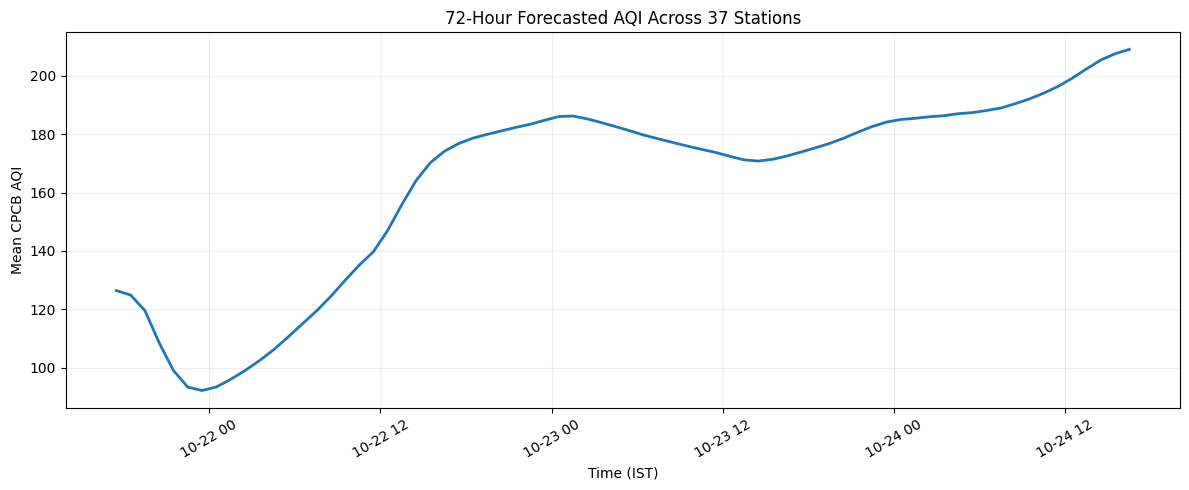

In [18]:
# ============================================================
# CELL 17 — 72H AQI Forecast
# ============================================================

import matplotlib.pyplot as plt

s = summary.copy()
s["time_ist"] = s.time.dt.tz_convert("Asia/Kolkata")

plt.figure(figsize=(12,5))
plt.plot(s.time_ist,s.mean_aqi,linewidth=2)
plt.xlabel("Time (IST)")
plt.ylabel("Mean CPCB AQI")
plt.title("72-Hour Forecasted AQI Across 37 Stations")
plt.xticks(rotation=30)
plt.grid(alpha=.2)
plt.tight_layout()

FIG_DIR.mkdir(parents=True,exist_ok=True)
plt.savefig(FIG_DIR/"fig17_72h_mean_aqi_forecast.png",dpi=600,bbox_inches="tight")
plt.show()

In [19]:
# ============================================================
# CELL 18 — Live XAI Explanation
# ============================================================

import inspect
import sys

sys.path.insert(0,str(XAI_DIR))
from pollusense_xai import explain_prediction

STATION_XAI="ST01"
POLLUTANT_XAI="pm25"

last_rows = (
    live.loc[live["time"] == latest]
    .set_index("location_id")
    .reindex(STATIONS)
)

last_value = float(last_rows.loc[STATION_XAI, POLLUTANT_XAI])

# Match Cell 10's residual reconstruction when the last concentration
# is unavailable for this station/pollutant.
if not np.isfinite(last_value):
    last_value = 0.0

print(
    f"XAI residual baseline for {STATION_XAI}/{POLLUTANT_XAI}: "
    f"{last_value:.5f}"
)

params=inspect.signature(explain_prediction).parameters

args={
    "model":model,"xseq":x_live,"edge_index":EDGE_INDEX,
    "edge_attr":EDGE_ATTR,"stations":STATIONS,"features":FEATURES,
    "targets":TARGETS,"station":STATION_XAI,"pollutant":POLLUTANT_XAI,
    "res_mean":res_mean,"res_std":res_std,"last_value":last_value,
    "background_hours":8,"top_k":10
}

args={k:v for k,v in args.items() if k in params}
xai=explain_prediction(**args)

print("="*64)
print("LIVE XAI EXPLANATION")
print("="*64)
print("Station:",xai["station"])
print("Pollutant:",xai["pollutant"].upper())
print("Prediction:",round(xai["prediction"],2),xai["unit"])
print("\nTop spatial contributors:")
for i,r in enumerate(xai["spatial_attention"][:5],1):
    print(f"{i}. {r['station']}: {r['attention']:.3f}")

print("\nTop positive SHAP:",", ".join(xai["top_positive_features"][:5]) or "None")
print("Top negative SHAP:",", ".join(xai["top_negative_features"][:5]) or "None")
print("\nExplanation:")
print(xai["natural_language"])

XAI residual baseline for ST01/pm25: 42.37000
LIVE XAI EXPLANATION
Station: ST01
Pollutant: PM25
Prediction: 44.29 µg/m³

Top spatial contributors:
1. ST11: 0.270
2. ST07: 0.258
3. ST20: 0.229
4. ST28: 0.060

Top positive SHAP: no2_history, pm25_history, co_lag1
Top negative SHAP: o3_history, hour_sin, pm10_history

Explanation:
For ST01, the GAT-LSTM predicted 44.29 µg/m³ for PM25. Positive SHAP values indicate features that increased the prediction relative to the explainer's background; negative values indicate features that decreased it. The leading positive contributors were no2_history, pm25_history, co_lag1. The leading negative contributors were o3_history, hour_sin, pm10_history. The strongest incoming spatial-attention weights were assigned to ST11, ST07, ST20. SHAP contributions and spatial attention describe model behavior, not physical causation.


In [20]:
# ============================================================
# CELL 19 — Frontend Response
# ============================================================

BACKEND_DIR.mkdir(parents=True,exist_ok=True)

current=live[live.time==latest].set_index("location_id").loc[STATION_XAI,TARGETS].to_dict()

forecast72=(
    forecast[forecast.location_id==STATION_XAI]
    .merge(forecast_aqi[forecast_aqi.location_id==STATION_XAI],on=["location_id","time"])
)

response={
    "station":STATION_XAI,
    "coordinates":{
        "lat":float(stations.set_index("location_id").loc[STATION_XAI,"latitude"]),
        "lng":float(stations.set_index("location_id").loc[STATION_XAI,"longitude"])
    },
    "generated_at_utc":str(latest),
    "current":{k:float(v) for k,v in current.items()},
    "next_hour":{
        "time_utc":str(forecast_utc),
        "time_ist":str(forecast_ist),
        **{k:float(v) for k,v in next_result.loc[STATION_XAI,TARGETS].items()},
        "AQI":int(next_result.loc[STATION_XAI,"AQI"]),
        "category":str(next_result.loc[STATION_XAI,"category"]),
        "dominant_pollutant":str(next_result.loc[STATION_XAI,"dominant"])
    },
    "forecast_72h":forecast72[
        ["time","pm25","pm10","co","no2","o3","so2","AQI","category","dominant_pollutant"]
    ].assign(time=lambda x:x.time.astype(str)).to_dict("records"),
    "xai":xai
}

with open(BACKEND_DIR/"live_response.json","w",encoding="utf-8") as f:
    json.dump(response,f,indent=2,ensure_ascii=False)

print("✓",BACKEND_DIR/"live_response.json")
print("Station:",STATION_XAI)
print("Forecast hours:",len(response["forecast_72h"]))
print("XAI:",bool(response["xai"]))

✓ c:\Users\udish\College\MajorProjectSem7\Implementation\backend\live_response.json
Station: ST01
Forecast hours: 72
XAI: True


In [21]:
# ============================================================
# CELL 20 — Frontend Prediction Function
# ============================================================

def predict_station(station_id):
    if station_id not in STATIONS:
        raise ValueError(f"Unknown station: {station_id}")

    f=forecast[forecast.location_id==station_id].merge(
        forecast_aqi[forecast_aqi.location_id==station_id],
        on=["location_id","time"],how="left"
    ).sort_values("time")

    f=f.iloc[::3].head(24)

    fc=[{
        "time_utc":str(r.time),
        "time_ist":str(pd.Timestamp(r.time).tz_convert("Asia/Kolkata")),
        "pollutants":{p:round(float(r[p]),3) for p in TARGETS},
        "cpcb_aqi":int(r.AQI),
        "category":str(r.category),
        "dominant_pollutant":str(r.dominant_pollutant)
    } for _,r in f.iterrows()]

    return {
        "station":station_id,
        "coordinates":{
            "lat":float(stations.set_index("location_id").loc[station_id,"latitude"]),
            "lng":float(stations.set_index("location_id").loc[station_id,"longitude"])
        },
        "generated_at_utc":str(latest),
        "generated_at_ist":str(latest.tz_convert("Asia/Kolkata")),
        "next_hour":{
            "time_ist":str(forecast_ist),
            "pollutants":{p:round(float(next_result.loc[station_id,p]),3) for p in TARGETS},
            "cpcb_aqi":int(next_result.loc[station_id,"AQI"]),
            "category":str(next_result.loc[station_id,"category"]),
            "dominant_pollutant":str(next_result.loc[station_id,"dominant"])
        },
        "forecast_72h":fc,
        "xai":xai if station_id==STATION_XAI else None
    }

result=predict_station("ST01")

print("Station:",result["station"])
print("Forecast points:",len(result["forecast_72h"]))
print("Next-hour AQI:",result["next_hour"]["cpcb_aqi"])
print("XAI included:",result["xai"] is not None)

Station: ST01
Forecast points: 24
Next-hour AQI: 130
XAI included: True


In [22]:
# ============================================================
# CELL 21 — Final Validation
# ============================================================

assert N==37
assert len(edges)==169
assert len(FEATURES)==34
assert len(TARGETS)==6
assert SEQ_LEN==24
assert x_live.shape==(1,24,37,46)
assert forecast.location_id.nunique()==37
assert forecast.time.nunique()==72
assert len(forecast)==37*72
assert forecast_aqi.shape[0]==37*72

print("="*60)
print("FINAL LIVE FORECAST VALIDATION PASSED")
print("="*60)
print("Stations:",N)
print("Edges:",len(edges))
print("Input:",x_live.shape)
print("72H rows:",len(forecast))
print("72H hours:",forecast.time.nunique())
print("AQI rows:",len(forecast_aqi))
print("✓ Recursive forecast ready")
print("✓ AQI calculation ready")
print("✓ XAI ready")
print("✓ Frontend response ready")



# ------------------------------------------------------------
# Extra live-forecast integrity checks
# ------------------------------------------------------------

assert not live.duplicated(["location_id", "time"]).any()
assert not forecast.duplicated(["location_id", "time"]).any()

assert len(live) == live["time"].nunique() * N
assert len(forecast) == 72 * N

assert np.isfinite(
    forecast[TARGETS].to_numpy(dtype=float)
).all()

assert (forecast[TARGETS].to_numpy(dtype=float) >= 0).all()

assert forecast_aqi["AQI"].notna().all()
assert forecast_aqi["category"].notna().all()
assert len(forecast_aqi) == 72 * N

assert cfg["aqi_window_hours"] == EXPECTED_WINDOWS

print("✓ Hourly station grid is unique and complete")
print("✓ Pollutant forecasts are finite and non-negative")
print("✓ AQI forecasts contain no incomplete windows")
print("✓ Saved CPCB averaging periods match the validated configuration")


FINAL LIVE FORECAST VALIDATION PASSED
Stations: 37
Edges: 169
Input: torch.Size([1, 24, 37, 46])
72H rows: 2664
72H hours: 72
AQI rows: 2664
✓ Recursive forecast ready
✓ AQI calculation ready
✓ XAI ready
✓ Frontend response ready
✓ Hourly station grid is unique and complete
✓ Pollutant forecasts are finite and non-negative
✓ AQI forecasts contain no incomplete windows
✓ Saved CPCB averaging periods match the validated configuration
